In [5]:
import zipfile
from pathlib import Path
import polars as pl

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")

zf = zipfile.ZipFile(RAW / "h-and-m-personalized-fashion-recommendations.zip")
image_files = [n for n in zf.namelist() if n.startswith("images/") and n.endswith(".jpg")]
image_ids = {Path(n).stem for n in image_files}
print("Images in zip:", len(image_ids))

labels = pl.read_parquet(PROCESSED / "labels_clean.parquet")
labels = labels.with_columns(
    pl.col("article_id").is_in(list(image_ids)).alias("has_image")
)
print(labels["has_image"].value_counts())

Images in zip: 105100
shape: (2, 2)
┌───────────┬────────┐
│ has_image ┆ count  │
│ ---       ┆ ---    │
│ bool      ┆ u32    │
╞═══════════╪════════╡
│ true      ┆ 104014 │
│ false     ┆ 440    │
└───────────┴────────┘


In [6]:
from PIL import Image
import random

random.seed(42)
sample = random.sample(image_files, 200)

sizes = []
for name in sample:
    with zf.open(name) as f:
        sizes.append(Image.open(f).size)

widths = [w for w, h in sizes]
heights = [h for w, h in sizes]
print("Width  range:", min(widths), "-", max(widths))
print("Height range:", min(heights), "-", max(heights))
print("Most common size:", max(set(sizes), key=sizes.count))

Width  range: 667 - 2805
Height range: 1749 - 1750
Most common size: (1166, 1750)


(2805, 1750) -> (256, 256)


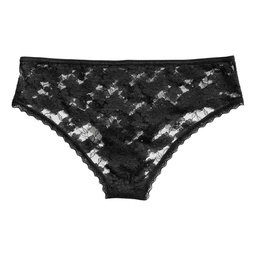

In [8]:
import sys
sys.path.append("..")
from src.data.make_images import pad_to_square, SIZE

wide = sample[widths.index(max(widths))]
with zf.open(wide) as f:
    img = Image.open(f).convert("RGB")

small = pad_to_square(img).resize((SIZE, SIZE), Image.Resampling.LANCZOS)
print(img.size, "->", small.size)
small